# Explicit Euler evolution

Euler–Maruyama begins with the deterministic explicit Euler method.
This notebook compares the Euler operator $I+\Delta t A$ with the exact
operator $e^{A\Delta t}$ and exposes its accuracy and stability limits.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Deterministic calculations

A scalar decay equation tests first-order convergence. A two-component
rotation shows that explicit Euler does not preserve the norm of a unitary or
Hamiltonian-like evolution.


In [2]:
decay_rate = 1.5
final_time = 4.0
trajectory_steps = (8, 20, 80)
decay_trajectories = {}

for step_count in trajectory_steps:
    time_step = final_time / step_count
    time = time_step * np.arange(step_count + 1)
    value = np.empty(step_count + 1)
    value[0] = 1.0
    for step in range(step_count):
        value[step + 1] = value[step] - decay_rate * value[step] * time_step
    decay_trajectories[step_count] = (time, value)

convergence_steps = 2 ** np.arange(4, 11)
convergence_dt = final_time / convergence_steps
final_error = np.abs(
    (1.0 - decay_rate * convergence_dt) ** convergence_steps
    - np.exp(-decay_rate * final_time)
)

angular_frequency = 2.0
rotation_dt = 0.04
rotation_step_count = 300
rotation_matrix = np.array([
    [0.0, -angular_frequency],
    [angular_frequency, 0.0],
])
euler_state = np.zeros((rotation_step_count + 1, 2))
exact_state = np.zeros_like(euler_state)
euler_state[0] = [1.0, 0.0]
exact_state[0] = [1.0, 0.0]
rotation_time = rotation_dt * np.arange(rotation_step_count + 1)

for step in range(rotation_step_count):
    euler_state[step + 1] = (
        np.eye(2) + rotation_dt * rotation_matrix
    ) @ euler_state[step]
    angle = angular_frequency * rotation_time[step + 1]
    exact_state[step + 1] = [np.cos(angle), np.sin(angle)]


## Verification

The scalar global error is first order. For pure rotation, explicit Euler has
amplification magnitude $\sqrt{1+(\omega\Delta t)^2}>1$, so its norm grows.


In [3]:
global_order = np.polyfit(
    np.log(convergence_dt), np.log(final_error), 1
)[0]
euler_norm = np.linalg.norm(euler_state, axis=1)
assert 0.90 < global_order < 1.10
assert euler_norm[-1] > 1.5
print(f"global convergence order = {global_order:.4f}")
print(f"final Euler rotation norm = {euler_norm[-1]:.4f}")


global convergence order = 0.9248
final Euler rotation norm = 2.6037


## Instructive plot

The plots separate accuracy from stability: smaller steps improve scalar
decay, while imaginary-axis eigenvalues remain outside the explicit-Euler
stability disk for every nonzero step.


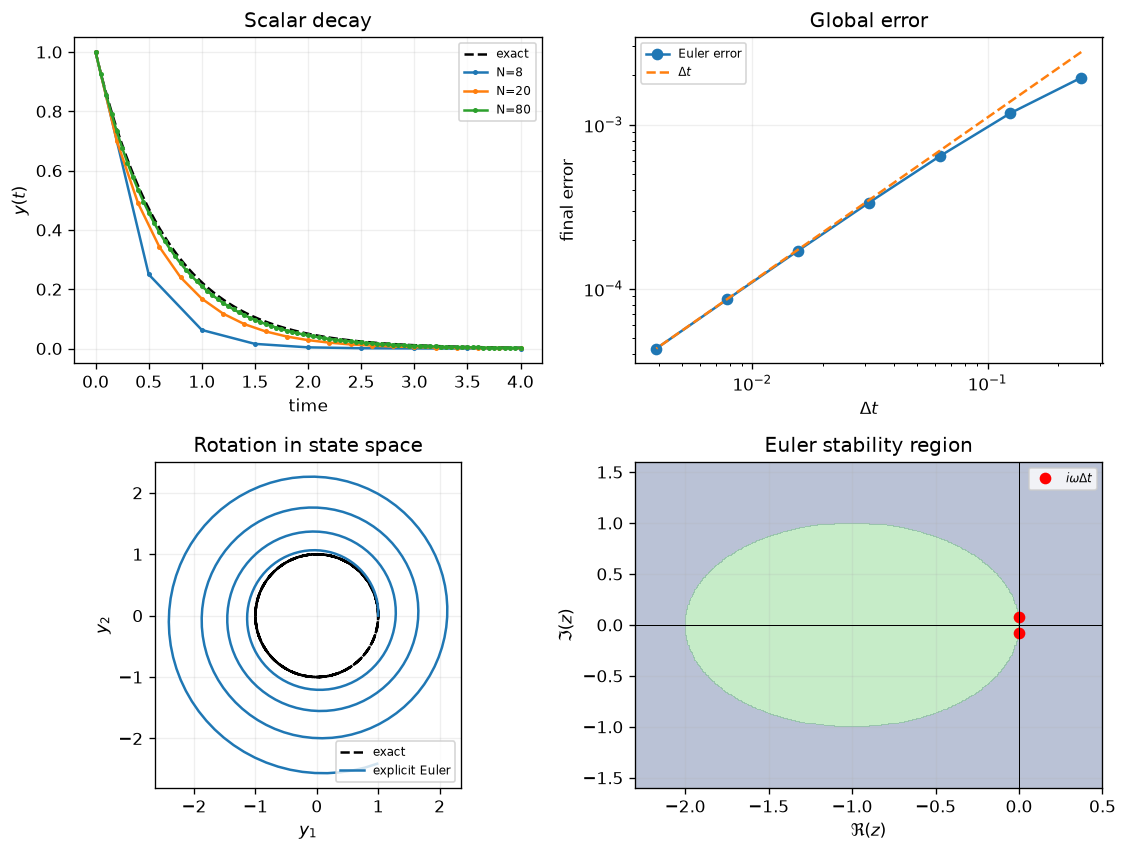

wrote lecture-notes/figures/08_brownian-motion-diffusion/05-explicit-euler-evolution.pdf


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(9.5, 7.2))

exact_time = np.linspace(0.0, final_time, 500)
axes[0, 0].plot(exact_time, np.exp(-decay_rate * exact_time), "k--", label="exact")
for step_count, (time, value) in decay_trajectories.items():
    axes[0, 0].plot(time, value, marker="o", markersize=2, label=f"N={step_count}")
axes[0, 0].set(title="Scalar decay", xlabel="time", ylabel=r"$y(t)$")
axes[0, 0].legend(fontsize=7)

axes[0, 1].loglog(convergence_dt, final_error, "o-", label="Euler error")
reference = final_error[-1] * convergence_dt / convergence_dt[-1]
axes[0, 1].loglog(convergence_dt, reference, "--", label=r"$\Delta t$")
axes[0, 1].set(title="Global error", xlabel=r"$\Delta t$", ylabel="final error")
axes[0, 1].legend(fontsize=7)

axes[1, 0].plot(exact_state[:, 0], exact_state[:, 1], "k--", label="exact")
axes[1, 0].plot(euler_state[:, 0], euler_state[:, 1], label="explicit Euler")
axes[1, 0].set(title="Rotation in state space", xlabel=r"$y_1$", ylabel=r"$y_2$")
axes[1, 0].set_aspect("equal", adjustable="box")
axes[1, 0].legend(fontsize=7)

real_axis = np.linspace(-2.3, 0.5, 350)
imag_axis = np.linspace(-1.6, 1.6, 350)
real_grid, imag_grid = np.meshgrid(real_axis, imag_axis)
stable = np.abs(1.0 + real_grid + 1j * imag_grid) <= 1.0
axes[1, 1].contourf(real_grid, imag_grid, stable, levels=[-0.5, 0.5, 1.5], alpha=0.35)
axes[1, 1].plot(0.0, angular_frequency * rotation_dt, "ro", label=r"$i\omega\Delta t$")
axes[1, 1].plot(0.0, -angular_frequency * rotation_dt, "ro")
axes[1, 1].axhline(0.0, color="black", linewidth=0.6)
axes[1, 1].axvline(0.0, color="black", linewidth=0.6)
axes[1, 1].set(title="Euler stability region", xlabel=r"$\Re(z)$", ylabel=r"$\Im(z)$")
axes[1, 1].legend(fontsize=7)

for axis in axes.flat:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "05-explicit-euler-evolution.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
